In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("RetailPulse - Day 5")
print("Sales Forecasting & Time Series Analysis")
print("Environment ready")

RetailPulse - Day 5
Sales Forecasting & Time Series Analysis
Environment ready


In [2]:
from pathlib import Path

file_path = Path(r"E:\data\processed\retail_cleaned.csv")

print("File exists:", file_path.exists())

df = pd.read_csv(file_path, parse_dates=["InvoiceDate"])

print("Dataset Shape:", df.shape)
print(df.head())

File exists: True


C:\Users\DRT-Admin\AppData\Local\Temp\ipykernel_6336\938523896.py:7: DtypeWarning: Columns (0: Invoice) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path, parse_dates=["InvoiceDate"])


Dataset Shape: (1007913, 8)
  Invoice StockCode                          Description  Quantity  \
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1  489434    79323P                   PINK CHERRY LIGHTS        12   
2  489434    79323W                  WHITE CHERRY LIGHTS        12   
3  489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   

          InvoiceDate  Price  Customer ID         Country  
0 2009-12-01 07:45:00   6.95      13085.0  United Kingdom  
1 2009-12-01 07:45:00   6.75      13085.0  United Kingdom  
2 2009-12-01 07:45:00   6.75      13085.0  United Kingdom  
3 2009-12-01 07:45:00   2.10      13085.0  United Kingdom  
4 2009-12-01 07:45:00   1.25      13085.0  United Kingdom  


In [3]:
# Calculate total sales
df["Revenue"] = df["Quantity"] * df["Price"]

# Remove cancelled invoices and invalid transactions
df_sales = df[
    (df["Quantity"] > 0) &
    (df["Price"] > 0) &
    (~df["Invoice"].astype(str).str.startswith("C"))
].copy()

# Aggregate sales by month
monthly_sales = (
    df_sales
    .set_index("InvoiceDate")["Revenue"]
    .resample("MS")
    .sum()
)

print("Monthly Sales:")
print(monthly_sales)

Monthly Sales:
InvoiceDate
2009-12-01     822483.950
2010-01-01     651155.112
2010-02-01     551504.726
2010-03-01     830915.261
2010-04-01     678875.252
2010-05-01     657705.500
2010-06-01     749537.310
2010-07-01     648810.270
2010-08-01     695251.910
2010-09-01     921696.991
2010-10-01    1161902.220
2010-11-01    1464293.142
2010-12-01     821452.730
2011-01-01     689811.610
2011-02-01     522545.560
2011-03-01     716215.260
2011-04-01     536968.491
2011-05-01     769296.610
2011-06-01     760547.010
2011-07-01     718076.121
2011-08-01     757841.380
2011-09-01    1056435.192
2011-10-01    1151263.730
2011-11-01    1503866.780
2011-12-01     637808.330
Freq: MS, Name: Revenue, dtype: float64


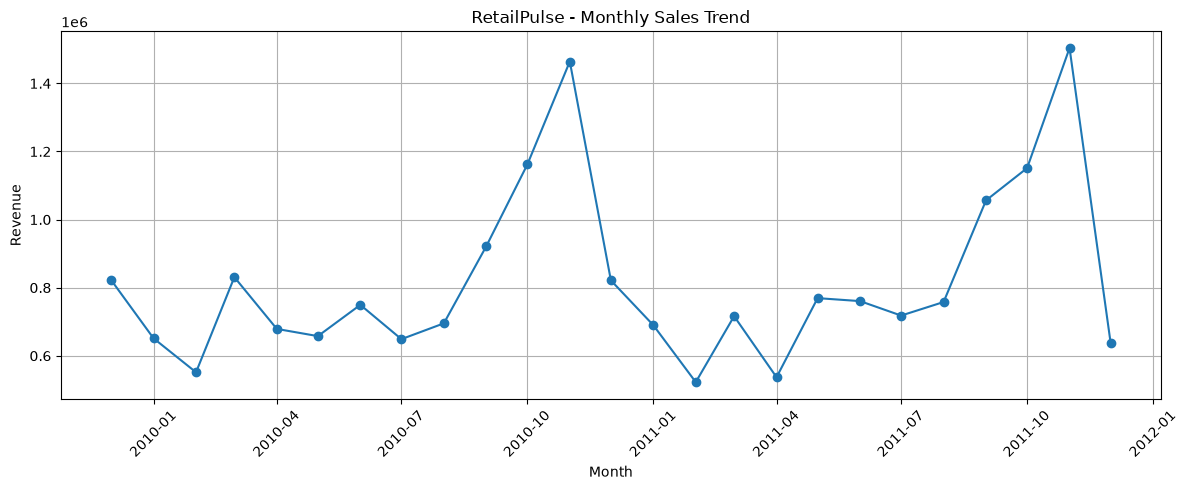

In [4]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o"
)

plt.title("RetailPulse - Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [5]:
# Calculate 3-month moving average
sales_analysis = monthly_sales.to_frame(name="Actual_Sales")

sales_analysis["3_Month_Moving_Average"] = (
    sales_analysis["Actual_Sales"].rolling(window=3).mean()
)

print(sales_analysis.tail(12))

             Actual_Sales  3_Month_Moving_Average
InvoiceDate                                      
2011-01-01     689811.610            9.918525e+05
2011-02-01     522545.560            6.779366e+05
2011-03-01     716215.260            6.428575e+05
2011-04-01     536968.491            5.919098e+05
2011-05-01     769296.610            6.741601e+05
2011-06-01     760547.010            6.889374e+05
2011-07-01     718076.121            7.493066e+05
2011-08-01     757841.380            7.454882e+05
2011-09-01    1056435.192            8.441176e+05
2011-10-01    1151263.730            9.885134e+05
2011-11-01    1503866.780            1.237189e+06
2011-12-01     637808.330            1.097646e+06


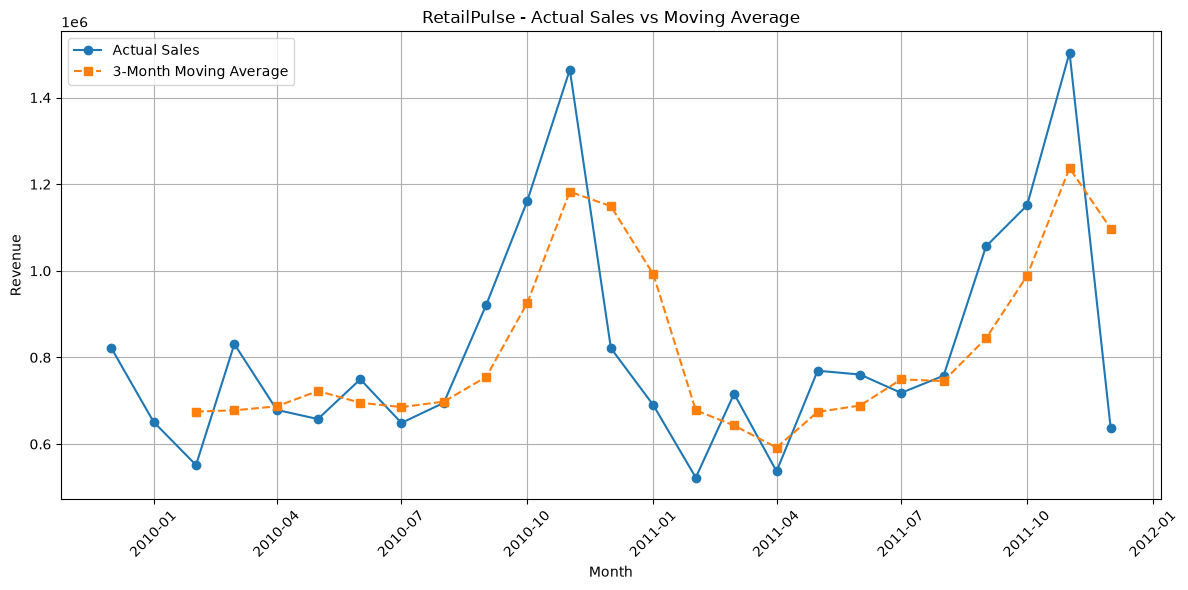

In [6]:
plt.figure(figsize=(12, 6))

plt.plot(
    sales_analysis.index,
    sales_analysis["Actual_Sales"],
    marker="o",
    label="Actual Sales"
)

plt.plot(
    sales_analysis.index,
    sales_analysis["3_Month_Moving_Average"],
    linestyle="--",
    marker="s",
    label="3-Month Moving Average"
)

plt.title("RetailPulse - Actual Sales vs Moving Average")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [7]:
# Forecast the next 3 months using the last 3-month average
last_3_month_avg = monthly_sales.tail(3).mean()

future_dates = pd.date_range(
    start=monthly_sales.index.max() + pd.offsets.MonthBegin(1),
    periods=3,
    freq="MS"
)

forecast = pd.Series(
    [last_3_month_avg] * 3,
    index=future_dates,
    name="Forecast_Revenue"
)

print("Baseline forecast for next 3 months:")
print(forecast.round(2))

Baseline forecast for next 3 months:
2012-01-01    1097646.28
2012-02-01    1097646.28
2012-03-01    1097646.28
Freq: MS, Name: Forecast_Revenue, dtype: float64


In [8]:
last_3_month_avg = monthly_sales.tail(3).mean()

future_dates = pd.date_range(
    start=monthly_sales.index.max() + pd.offsets.MonthBegin(1),
    periods=3,
    freq="MS"
)

forecast = pd.Series(
    [last_3_month_avg] * 3,
    index=future_dates,
    name="Forecast_Revenue"
)

print("Next 3 Months Sales Forecast")
print(forecast.round(2))

Next 3 Months Sales Forecast
2012-01-01    1097646.28
2012-02-01    1097646.28
2012-03-01    1097646.28
Freq: MS, Name: Forecast_Revenue, dtype: float64


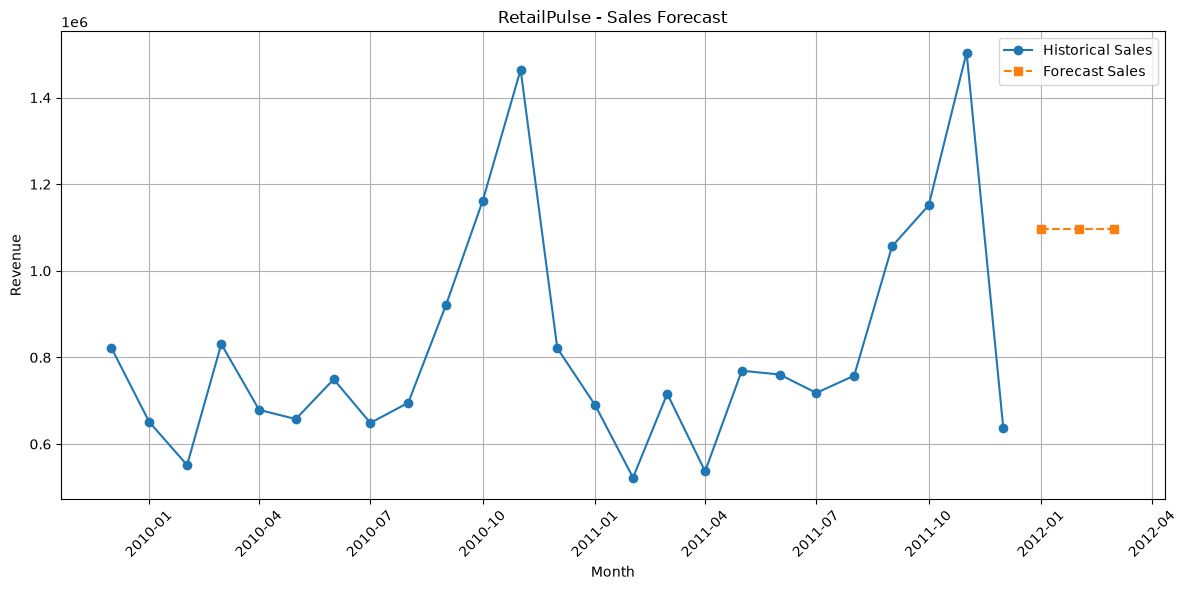

In [9]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    label="Historical Sales"
)

plt.plot(
    forecast.index,
    forecast.values,
    marker="s",
    linestyle="--",
    label="Forecast Sales"
)

plt.title("RetailPulse - Sales Forecast")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [10]:
print("===== RETAILPULSE DAY 5 INSIGHTS =====")

print(f"Total Revenue: {monthly_sales.sum():,.2f}")
print(f"Average Monthly Revenue: {monthly_sales.mean():,.2f}")
print(f"Highest Sales Month: {monthly_sales.idxmax():%B %Y}")
print(f"Highest Monthly Revenue: {monthly_sales.max():,.2f}")
print(f"Baseline Forecast per Month: {last_3_month_avg:,.2f}")

print("\nBusiness Recommendations:")
print("1. Plan inventory according to historical sales trends.")
print("2. Prepare stock for months with higher demand.")
print("3. Monitor sales drops and investigate their causes.")
print("4. Treat baseline forecasts as estimates, not guarantees.")

===== RETAILPULSE DAY 5 INSIGHTS =====
Total Revenue: 20,476,260.45
Average Monthly Revenue: 819,050.42
Highest Sales Month: November 2011
Highest Monthly Revenue: 1,503,866.78
Baseline Forecast per Month: 1,097,646.28

Business Recommendations:
1. Plan inventory according to historical sales trends.
2. Prepare stock for months with higher demand.
3. Monitor sales drops and investigate their causes.
4. Treat baseline forecasts as estimates, not guarantees.
